# Session 11 lab: Are deliveries on time?

<p class="lead">
Build an on-time rate that counts every shipment that was due, including the ones still stuck in transit. Then compare carriers and warehouses fairly, describe delivery times and the backlog, fix three broken dashboards and recommend one process for the operations manager to investigate.
</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aayush181509/AnalyticsLecture/blob/main/notebooks/11_operations_service_lab.ipynb)

Open this notebook in Google Colab with the button above, then run each cell from top to bottom with **Shift + Enter**. Save your own copy with **File → Save a copy in Drive**.

---

## The business decision

> *Operations manager: "Customers are complaining about late deliveries, and December felt terrible. I can afford one improvement project next quarter. Tell me which carrier or warehouse process to investigate first, what the evidence is, and what else we would need to check before we blame anyone."*

Your answer must rest on numbers the manager can trust: the right denominator, visible volumes, a view of the late work still open, and comparisons that are not distorted by mix or by small groups.

> **About the data**
>
> **`shipments.csv`** (operations-v1) is **synthetic** teaching data generated by the course: a fictional retailer's outbound shipments dispatched in 2025, from three fictional warehouses with three fictional carriers. One row per **shipment**. It is a **snapshot at the end of 31 December 2025** (the **cutoff**): a blank `delivered_date` means "not delivered by the cutoff", not "never".

---

## How this lab works

| Part | What you do | Tasks |
|---|---|---|
| **Guided practice** | Follow along step by step, everyone together | G1–G4 |
| **Independent tasks** | Same skills, new questions, on your own or in pairs | I1–I6 |
| **Challenge** | Debugging and a recommendation | C1–C2 |

Each task has a level:

- **Core**: everyone completes it; it is enough for your portfolio.
- **Stretch**: for when you finish the core tasks early.
- **Challenge**: optional, harder reasoning.

---

## What you will be able to do

1. Check a snapshot's keys, statuses and date order before measuring anything.
2. Build the due, not-yet-due and unknown-promise populations and reconcile them to the total.
3. Calculate an on-time rate whose denominator includes overdue shipments still pending.
4. Compare carriers and warehouses as ratios of counts, with due volumes and carrier mix visible.
5. Describe completed-shipment lead times with mean, median and 90th percentile.
6. Measure the overdue backlog and its age.
7. Find and fix three common service-dashboard bugs.
8. Recommend one process investigation, with its evidence and its limits.

**Evidence you keep:** a carrier comparison, a lead-time distribution, a backlog summary and a short recommendation.

---

## Before you start

- Read the [Session 11 lecture](11_operations_service_lecture.md).
- Re-read the weighted-rate and Simpson's paradox parts of the [Session 5 lecture](05_metrics_and_kpis_lecture.md).

Run both setup cells.

In [1]:
# Operations data setup (synthetic). Run this cell first.
# Downloads the course's synthetic shipment data from GitHub and checks it is the exact version this course uses.
import hashlib
import io
import os
import urllib.request

import pandas as pd

OPERATIONS_URL = "https://raw.githubusercontent.com/Aayush181509/AnalyticsLecture/main/data/synthetic/operations-v1/"
OPERATIONS_SHA256 = {"shipments.csv": "7b5c0860beb2a16ba4f84a3dd0b5bdf9d88e968b720c6541f1dcb7d688c75687"}
OPERATIONS_DIR = os.environ.get("COURSE_OPERATIONS_DIR", "")
CUTOFF = pd.Timestamp("2025-12-31")


def load_shipments():
    """Load operations-v1 shipments: one row per shipment, known at the end of 2025-12-31."""
    if OPERATIONS_DIR:
        with open(os.path.join(OPERATIONS_DIR, "shipments.csv"), "rb") as f:
            data = f.read()
    else:
        data = urllib.request.urlopen(OPERATIONS_URL + "shipments.csv").read()
    if hashlib.sha256(data).hexdigest() != OPERATIONS_SHA256["shipments.csv"]:
        print("WARNING: this file differs from the course version. Ask your facilitator.")
    return pd.read_csv(io.BytesIO(data), parse_dates=["dispatch_date", "promised_date", "delivered_date"])


print("Operations setup complete.")

Operations setup complete.


In [2]:
import matplotlib.pyplot as plt
import numpy as np

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a"]),
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
print("Plot style ready.")

Plot style ready.


---

## Guided practice

### G1 (Core): Load and check the snapshot

Before any rate, check four things: one row per shipment, what the statuses are, whether statuses agree with the dates, and whether the dates are in a possible order.

In [3]:
shipments = load_shipments()
print("Rows:", len(shipments))
print("shipment_id unique:", shipments["shipment_id"].is_unique, "| order_id unique:", shipments["order_id"].is_unique)
print()
print(shipments["status"].value_counts().to_string())
shipments[["shipment_id", "order_id", "carrier", "dispatch_date", "promised_date", "delivered_date", "status"]].head()

Rows: 5893
shipment_id unique: True | order_id unique: False

status
delivered     5603
in_transit     250
canceled        40


,shipment_id,order_id,carrier,dispatch_date,promised_date,delivered_date,status
0,SHP-00001,ORD-00001,ParcelOne,2025-01-01,2025-01-03,2025-01-03,delivered
1,SHP-00002,ORD-00002,SwiftRoute,2025-01-01,2025-01-06,2025-01-04,delivered
2,SHP-00003,ORD-00003,ParcelOne,2025-01-01,2025-01-06,2025-01-05,delivered
3,SHP-00004,ORD-00004,SwiftRoute,2025-01-01,2025-01-06,2025-01-18,delivered
4,SHP-00005,ORD-00005,Regional Express,2025-01-01,2025-01-06,2025-01-04,delivered


> **Your turn:** change the code in the next cell and run it again.

In [4]:
# 1. Run the cell. Does every 'delivered' row have a delivered_date? Does any other status have one?
# 2. Change check_column to "promised_date". Which status has blank promise dates?
# 3. Read the date checks. Which counts must be zero, and which are allowed to be above zero?
check_column = "delivered_date"

print(f"Blank {check_column} by status:")
display(pd.crosstab(shipments["status"], shipments[check_column].isna().map({True: "blank", False: "known"})))

date_checks = pd.Series({
    "delivered before dispatch": (shipments["delivered_date"] < shipments["dispatch_date"]).sum(),
    "promised before dispatch": (shipments["promised_date"] < shipments["dispatch_date"]).sum(),
    "dispatched after cutoff": (shipments["dispatch_date"] > CUTOFF).sum(),
    "delivered after cutoff": (shipments["delivered_date"] > CUTOFF).sum(),
    "promised after cutoff": (shipments["promised_date"] > CUTOFF).sum(),
}, name="rows")
date_checks

Blank delivered_date by status:


delivered_date,blank,known
status,,
canceled,40,0
delivered,0,5603
in_transit,250,0


delivered before dispatch     0
promised before dispatch      0
dispatched after cutoff       0
delivered after cutoff        0
promised after cutoff        99
Name: rows, dtype: int64

> **What do you notice?**
>
> Write one line for each check in your evidence log: "passed", or "not an error, because…". A check you skip is a problem you will find later, in front of a manager.

### G2 (Core): Build the populations and reconcile them

Every shipment goes into exactly one group at the cutoff:

| Group | Rule | In the on-time rate? |
|---|---|---|
| `canceled` | status is canceled | No |
| `unknown promise` | promise date blank | No, but count it |
| `not yet due` | promised **after** the cutoff | No, even if already delivered |
| `due` | promised **on or before** the cutoff | **Yes**, delivered or not |

In [5]:
def add_service_columns(df, cutoff=CUTOFF):
    """Label each shipment's population at the cutoff and add on-time, pending and lead-time columns."""
    out = df.copy()
    out["population"] = np.select(
        [out["status"] == "canceled", out["promised_date"].isna(), out["promised_date"] > cutoff],
        ["canceled", "unknown promise", "not yet due"],
        default="due",
    )
    delivered = out["delivered_date"].notna()
    out["on_time"] = delivered & (out["delivered_date"] <= out["promised_date"])
    out["pending"] = ~delivered & (out["status"] != "canceled")
    overdue = (out["population"] == "due") & out["pending"]
    out["days_past_due"] = (cutoff - out["promised_date"]).dt.days.clip(lower=0).where(overdue)
    out["lead_days"] = (out["delivered_date"] - out["dispatch_date"]).dt.days
    out["promised_month"] = out["promised_date"].dt.to_period("M")
    return out


s = add_service_columns(shipments)
due = s[s["population"] == "due"]
print("Service columns added.")

Service columns added.


> **Your turn:** change the code in the next cell and run it again.

In [6]:
# 1. Run the cell. Do the four groups add up to all shipments? Do due + not yet due + unknown promise add up to eligible?
# 2. Change show to "not yet due". How many of them were already delivered? Why are they still excluded?
# 3. Change show to "unknown promise". What status do they have? Write one sentence a manager would read about them.
show = "due"

groups = s.pivot_table(index="population", columns="status", values="shipment_id", aggfunc="count", fill_value=0, margins=True, margins_name="All")
display(groups)

eligible = s[s["population"] != "canceled"]
print("All groups add up to all shipments:", groups.loc["All", "All"] == len(s))
print("Eligible:", len(eligible), "| due + not yet due + unknown promise:",
      (s["population"].isin(["due", "not yet due", "unknown promise"])).sum())
print()
print(f"First rows of '{show}':")
s.loc[s["population"] == show, ["shipment_id", "carrier", "dispatch_date", "promised_date", "delivered_date", "status"]].head()

status,canceled,delivered,in_transit,All
population,,,,
canceled,40,0,0,40
due,0,5585,157,5742
not yet due,0,6,93,99
unknown promise,0,12,0,12
All,40,5603,250,5893


All groups add up to all shipments: True
Eligible: 5853 | due + not yet due + unknown promise: 5853

First rows of 'due':


,shipment_id,carrier,dispatch_date,promised_date,delivered_date,status
0,SHP-00001,ParcelOne,2025-01-01,2025-01-03,2025-01-03,delivered
1,SHP-00002,SwiftRoute,2025-01-01,2025-01-06,2025-01-04,delivered
2,SHP-00003,ParcelOne,2025-01-01,2025-01-06,2025-01-05,delivered
3,SHP-00004,SwiftRoute,2025-01-01,2025-01-06,2025-01-18,delivered
4,SHP-00005,Regional Express,2025-01-01,2025-01-06,2025-01-04,delivered


> **Reconcile before you report**
>
> The table above is your **reconciliation**: every shipment is counted once, and you can say exactly how many were left out of the rate and why. Keep it in your evidence log.

### G3 (Core): The on-time rate, overall

On-time rate = on-time **due** shipments ÷ **all due** shipments, including those still pending.

In [7]:
on_time = due["on_time"].sum()
pending_due = due["pending"].sum()
on_time_rate = on_time / len(due)

print(f"Due shipments:                   {len(due)}")
print(f"  delivered on time:             {on_time}")
print(f"  delivered late:                {(due['delivered_date'].notna() & ~due['on_time']).sum()}")
print(f"  still pending (overdue/today): {pending_due}")
print(f"On-time rate: {on_time} / {len(due)} = {on_time_rate:.1%}")
print()
delivered_only = due[due["delivered_date"].notna()]
print(f"Delivered-only rate (wrong):     {delivered_only['on_time'].mean():.1%} from {len(delivered_only)} shipments")

Due shipments:                   5742
  delivered on time:             4700
  delivered late:                885
  still pending (overdue/today): 157
On-time rate: 4700 / 5742 = 81.9%

Delivered-only rate (wrong):     84.2% from 5585 shipments


Write the result as a sentence in your evidence log, with the numerator, the denominator and what was excluded:

> *"As of 31 December 2025, ___% of the ___ shipments due by then were delivered on time; ___ still pending are counted as late. ___ shipments promised for January and ___ with no recorded promise are not included."*

### G4 (Core): The on-time rate by month

Group by **promised month**: the month the deadline fell in. Each month's rate is a ratio of that month's counts.

> **Your turn:** change the code in the next cell and run it again.

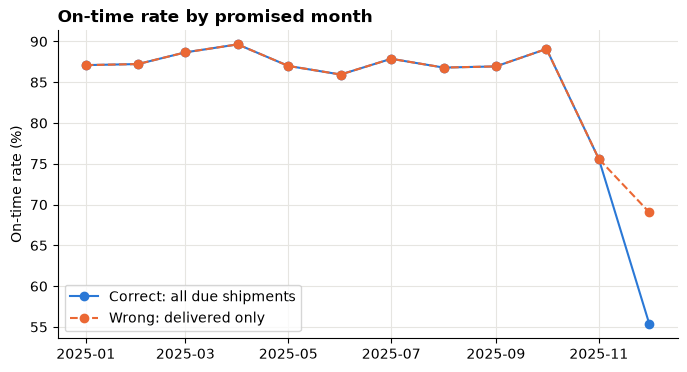

,due,on_time,pending,on_time_rate,delivered_only_rate
promised_month,,,,,
2025-01,372,324,0,87.1%,87.1%
2025-02,415,362,0,87.2%,87.2%
2025-03,441,391,0,88.7%,88.7%
2025-04,415,372,0,89.6%,89.6%
2025-05,423,368,0,87.0%,87.0%
2025-06,434,373,0,85.9%,85.9%
2025-07,470,413,0,87.9%,87.9%
2025-08,462,401,0,86.8%,86.8%
2025-09,490,426,0,86.9%,86.9%


In [8]:
# 1. Run the cell. Which month is worst? In which months do the two lines differ, and why only there?
# 2. Change group_col to "dispatch_month". Does the picture change? Which grouping answers "how did we do on promises due in December"?
# 3. Find the month with the most due shipments. Is it also the worst month?
group_col = "promised_month"

data = s.assign(dispatch_month=s["dispatch_date"].dt.to_period("M"))
due_m = data[data["population"] == "due"]
monthly = due_m.groupby(group_col).agg(due=("on_time", "size"), on_time=("on_time", "sum"), pending=("pending", "sum"))
monthly["on_time_rate"] = monthly["on_time"] / monthly["due"]
delivered_m = due_m[due_m["delivered_date"].notna()].groupby(group_col)["on_time"].mean()
monthly["delivered_only_rate"] = delivered_m

ax = plt.gca()
x = monthly.index.to_timestamp()
ax.plot(x, monthly["on_time_rate"] * 100, marker="o", label="Correct: all due shipments")
ax.plot(x, monthly["delivered_only_rate"] * 100, marker="o", linestyle="--", label="Wrong: delivered only")
ax.set_title(f"On-time rate by {group_col.replace('_', ' ')}")
ax.set_ylabel("On-time rate (%)")
ax.legend(loc="lower left")
plt.show()
monthly.assign(on_time_rate=monthly["on_time_rate"].map("{:.1%}".format),
               delivered_only_rate=monthly["delivered_only_rate"].map("{:.1%}".format))

> **Hint**
>
> The two lines can only differ in months that still have **pending** shipments at the cutoff. Grouping by dispatch month mixes shipments whose deadlines fell in different months, so it answers a different question.

---

## Independent tasks

### I1 (Core): Carriers and warehouses, with due counts

The function below makes a service table for any grouping: due count, on-time count, pending count and the on-time rate as a **ratio of counts**. A group with nothing due gets "n/a", not 0%.

In [9]:
def service_table(df, by):
    """On-time rate as a ratio of counts for each group, with the due count visible."""
    due_rows = df[df["population"] == "due"]
    t = due_rows.groupby(by).agg(due=("on_time", "size"), on_time=("on_time", "sum"), pending=("pending", "sum"))
    t["on_time_rate"] = t["on_time"] / t["due"].where(t["due"] > 0)
    return t


def show_rates(t):
    """Format the rate column for reading, with n/a for empty groups."""
    return t.assign(on_time_rate=t["on_time_rate"].map(lambda r: "n/a" if pd.isna(r) else f"{r:.1%}"))

> **Your turn:** change the code in the next cell and run it again.

In [10]:
# 1. Run the cell. Which carrier has the lowest on-time rate? How many due shipments is that rate based on?
# 2. Change group_by to "warehouse". Which warehouse looks worst?
# 3. Change group_by to "service". Is Express more or less reliable than Standard?
group_by = "carrier"

t = service_table(s, group_by)
print(f"Overall (ratio of counts):      {t['on_time'].sum() / t['due'].sum():.1%}")
print(f"Mean of the group percentages:  {t['on_time_rate'].mean():.1%}   <- not the overall rate")
show_rates(t)

Overall (ratio of counts):      81.9%
Mean of the group percentages:  82.0%   <- not the overall rate


,due,on_time,pending,on_time_rate
carrier,,,,
ParcelOne,2059,1524,129,74.0%
Regional Express,1259,1075,8,85.4%
SwiftRoute,2424,2101,20,86.7%


### I2 (Core): Warehouse × carrier, and the carrier mix

The worst-looking warehouse in I1 might simply use the weakest carrier more. Look **inside** each carrier.

> **Your turn:** change the code in the next cell and run it again.

In [11]:
# 1. Run the cell. Within each carrier, how different are the three warehouses?
# 2. Which warehouse sends the largest share of its shipments with the weakest carrier?
# 3. Write two sentences: is the worst warehouse's problem its own process or its carrier mix? Use the mix-adjusted rates.
rows, cols = "warehouse", "carrier"

wc = service_table(s, [rows, cols])
rates = wc["on_time_rate"].unstack(cols)
volume = wc["due"].unstack(cols)
share = volume.div(volume.sum(axis=1), axis=0)

half = 1.96 * np.sqrt(wc["on_time_rate"] * (1 - wc["on_time_rate"]) / wc["due"])
wc_display = wc[["due", "on_time_rate"]].assign(low=(wc["on_time_rate"] - half).map("{:.1%}".format),
                                               high=(wc["on_time_rate"] + half).map("{:.1%}".format))

company_mix = volume.sum() / volume.sum().sum()
overall = service_table(s, rows)
print("On-time rate:"); display(rates.map("{:.1%}".format))
print("Share of each row's due shipments:"); display(share.map("{:.0%}".format))
print("Actual rate vs rate with the company's overall mix:")
display(pd.DataFrame({"actual": overall["on_time_rate"], "company mix": (rates * company_mix).sum(axis=1)}).map("{:.1%}".format))
print("Every cell, with due count and approximate 95% interval:")
show_rates(wc_display)

On-time rate:


carrier,ParcelOne,Regional Express,SwiftRoute
warehouse,,,
Central hub,72.4%,85.5%,86.6%
North hub,75.1%,85.1%,87.0%
South hub,74.5%,85.8%,85.3%


Share of each row's due shipments:


carrier,ParcelOne,Regional Express,SwiftRoute
warehouse,,,
Central hub,29%,25%,46%
North hub,21%,23%,56%
South hub,69%,16%,15%


Actual rate vs rate with the company's overall mix:


,actual,company mix
warehouse,,
Central hub,82.2%,81.3%
North hub,84.1%,82.3%
South hub,78.0%,81.5%


Every cell, with due count and approximate 95% interval:


due on_time_rate    low   high
warehouse   carrier                                          
Central hub ParcelOne          605        72.4%  68.8%  76.0%
            Regional Express   518        85.5%  82.5%  88.6%
            SwiftRoute         967        86.6%  84.4%  88.7%
North hub   ParcelOne          454        75.1%  71.1%  79.1%
            Regional Express   502        85.1%  81.9%  88.2%
            SwiftRoute        1239        87.0%  85.1%  88.9%
South hub   ParcelOne         1000        74.5%  71.8%  77.2%
            Regional Express   239        85.8%  81.3%  90.2%
            SwiftRoute         218        85.3%  80.6%  90.0%

> **Small groups**
>
> Look at the due counts and intervals in the last table. A cell with a couple of hundred due shipments has an interval several points wide. Do not rank cells whose intervals overlap heavily; say "not shown" instead.

### I3 (Core): Lead time by service, completed shipments only

Lead time = delivered − dispatched, in calendar days. It exists only for shipments that were delivered, so always report it as "completed shipments" with the count.

> **Your turn:** change the code in the next cell and run it again.

,completed,mean,median,p90,max
service,,,,,
Express,1200,3.08,2.00,4.00,24.00
Standard,4403,4.90,4.00,6.00,26.00


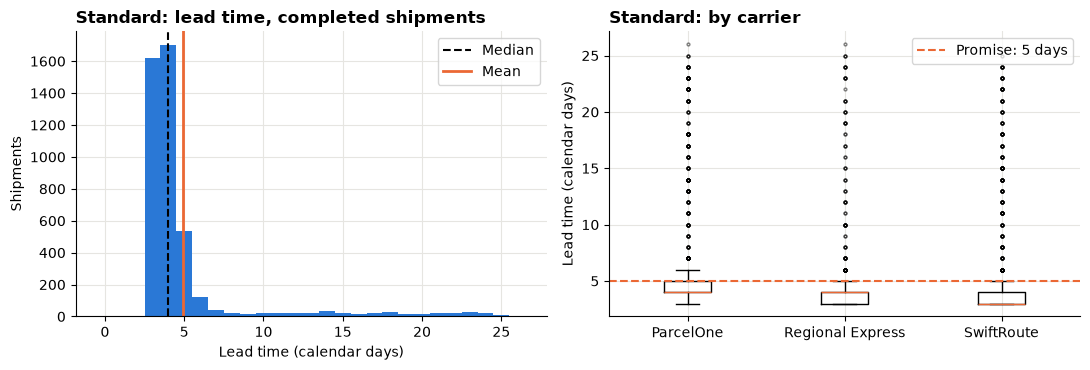

In [12]:
# 1. Run the cell. For each service, how far apart are the mean and the median? Why?
# 2. Change by to ["service", "carrier"]. Which carrier has the longest 90th percentile for Standard?
# 3. Change service_to_plot to "Express". Draw the promise line at 2 days instead of 5 (edit promise_days).
by = "service"
service_to_plot = "Standard"
promise_days = 5

completed = s[s["delivered_date"].notna()]
lead = completed.groupby(by)["lead_days"].agg(
    completed="count", mean="mean", median="median", p90=lambda x: x.quantile(0.9), max="max")
display(lead)

part = completed[completed["service"] == service_to_plot]
carriers = sorted(part["carrier"].unique())
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.hist(part["lead_days"], bins=np.arange(0, part["lead_days"].max() + 2) - 0.5)
ax1.axvline(part["lead_days"].median(), color="black", linestyle="--", label="Median")
ax1.axvline(part["lead_days"].mean(), color="#eb6834", linewidth=2, label="Mean")
ax1.set_title(f"{service_to_plot}: lead time, completed shipments")
ax1.set_xlabel("Lead time (calendar days)")
ax1.set_ylabel("Shipments")
ax1.legend()
ax2.boxplot([part.loc[part["carrier"] == c, "lead_days"] for c in carriers],
            flierprops={"marker": ".", "markersize": 4, "alpha": 0.5})
ax2.set_xticks(range(1, len(carriers) + 1), carriers)
ax2.axhline(promise_days, color="#eb6834", linestyle="--", label=f"Promise: {promise_days} days")
ax2.set_title(f"{service_to_plot}: by carrier")
ax2.set_ylabel("Lead time (calendar days)")
ax2.legend()
fig.tight_layout()
plt.show()

> **What the chart leaves out**
>
> Shipments still pending at the cutoff have no lead time, and they are the slow ones. So completed-only lead times are **optimistic**. Say so in one sentence under your chart.

### I4 (Core): The oldest overdue pending shipments

Days past due = cutoff − promised date for **due** shipments still **pending**, never below 0. Due today and still pending = 0 days, but still late.

> **Your turn:** change the code in the next cell and run it again.

In [13]:
# 1. Run the cell. Which carrier owns most of the overdue backlog? How old is its oldest shipment?
# 2. Change n_oldest to 20. Are the oldest shipments spread across carriers and warehouses, or concentrated?
# 3. Change backlog_by to "warehouse". Does the backlog follow the carrier or the warehouse?
n_oldest = 10
backlog_by = "carrier"

backlog = s[(s["population"] == "due") & s["pending"]]
summary = backlog.groupby(backlog_by)["days_past_due"].agg(
    pending_due="count", median_days_past_due="median", max_days_past_due="max")
summary["due_today"] = backlog[backlog["days_past_due"] == 0].groupby(backlog_by).size()
display(summary.fillna({"due_today": 0}))

backlog.sort_values(["days_past_due", "shipment_id"], ascending=[False, True]).head(n_oldest)[
    ["shipment_id", "warehouse", "carrier", "service", "promised_date", "days_past_due"]
].astype({"days_past_due": int})

,pending_due,median_days_past_due,max_days_past_due,due_today
carrier,,,,
ParcelOne,129,7.00,20.00,6
Regional Express,8,2.50,7.00,2
SwiftRoute,20,3.00,19.00,5


,shipment_id,warehouse,carrier,service,promised_date,days_past_due
5320,SHP-05321,South hub,ParcelOne,Express,2025-12-11,20
5277,SHP-05278,North hub,SwiftRoute,Standard,2025-12-12,19
5305,SHP-05306,Central hub,ParcelOne,Standard,2025-12-13,18
5326,SHP-05327,South hub,ParcelOne,Standard,2025-12-14,17
5327,SHP-05328,South hub,ParcelOne,Standard,2025-12-14,17
5413,SHP-05414,South hub,ParcelOne,Express,2025-12-14,17
5418,SHP-05419,North hub,ParcelOne,Express,2025-12-14,17
5344,SHP-05345,Central hub,ParcelOne,Standard,2025-12-15,16
5347,SHP-05348,South hub,ParcelOne,Standard,2025-12-15,16
5348,SHP-05349,Central hub,ParcelOne,Standard,2025-12-15,16


### I5 (Stretch): Count shipments, not orders

One order can be split into two shipments. How many orders are split, and could a split order be half on time and half late?

> **Your turn:** change the code in the next cell and run it again.

In [14]:
# 1. Run the cell. How many due orders have more than one due shipment? How many of those are "half on time"?
# 2. Compare the number of due shipments with the number of due orders. Which one did the carriers actually deliver?
# 3. Change show_mixed to False to see split orders that were fully on time or fully late.
show_mixed = True

per_order = due.groupby("order_id").agg(shipments=("shipment_id", "count"), on_time=("on_time", "sum"))
split = per_order[per_order["shipments"] > 1]
mixed = split[(split["on_time"] > 0) & (split["on_time"] < split["shipments"])]

print(f"Due shipments: {len(due)} | due orders: {len(per_order)}")
print(f"Split orders (2+ due shipments): {len(split)} | of which partly on time, partly late: {len(mixed)}")
chosen = mixed.index if show_mixed else split.drop(mixed.index).index
due[due["order_id"].isin(chosen[:3])][["order_id", "shipment_id", "carrier", "promised_date", "delivered_date", "on_time"]]

Due shipments: 5742 | due orders: 5071
Split orders (2+ due shipments): 671 | of which partly on time, partly late: 154


,order_id,shipment_id,carrier,promised_date,delivered_date,on_time
31,ORD-00030,SHP-00032,ParcelOne,2025-01-08,2025-01-07,True
39,ORD-00030,SHP-00040,ParcelOne,2025-01-09,2025-01-26,False
123,ORD-00111,SHP-00124,ParcelOne,2025-01-11,2025-01-14,False
136,ORD-00122,SHP-00137,SwiftRoute,2025-01-15,2025-01-16,False
154,ORD-00111,SHP-00155,ParcelOne,2025-01-14,2025-01-14,True
155,ORD-00122,SHP-00156,SwiftRoute,2025-01-17,2025-01-15,True


### I6 (Stretch): How sure are the carrier gaps?

Use the approximate interval from [Session 9](09_sampling_and_experiments_lecture.md): *rate ± 1.96 × √(rate × (1 − rate) ÷ due)*. The shipments are not a random sample, so read the interval as "how much this rate could move by chance from one period to the next".

> **Your turn:** change the code in the next cell and run it again.

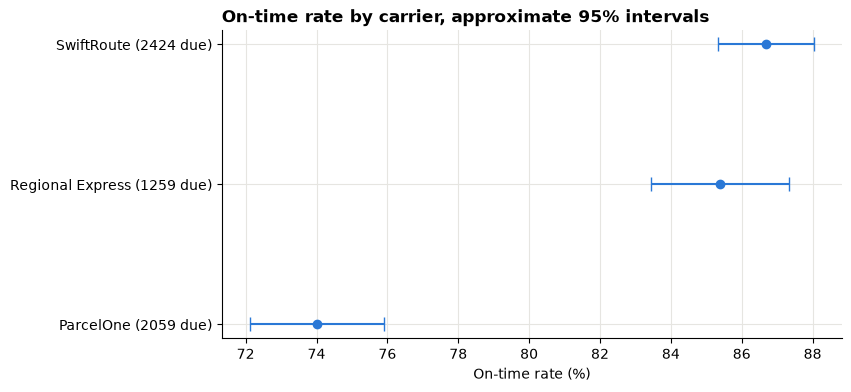

,due,on_time,pending,on_time_rate,low,high
carrier,,,,,,
ParcelOne,2059,1524,129,74.0%,72.1%,75.9%
Regional Express,1259,1075,8,85.4%,83.4%,87.3%
SwiftRoute,2424,2101,20,86.7%,85.3%,88.0%


In [15]:
# 1. Run the cell. Do the intervals of the weakest carrier and the others overlap?
# 2. Change months to [12]. With only December's due shipments, how much wider are the intervals?
# 3. Change group_by to "warehouse" (with all months). Which warehouse gaps survive the intervals?
group_by = "carrier"
months = list(range(1, 13))

subset = s[s["promised_date"].dt.month.isin(months)]
t = service_table(subset, group_by)
half = 1.96 * np.sqrt(t["on_time_rate"] * (1 - t["on_time_rate"]) / t["due"])

ax = plt.gca()
ax.errorbar(t["on_time_rate"] * 100, range(len(t)), xerr=half * 100, fmt="o", capsize=5)
ax.set_yticks(range(len(t)), [f"{g} ({n} due)" for g, n in zip(t.index, t["due"])])
ax.set_title(f"On-time rate by {group_by}, approximate 95% intervals")
ax.set_xlabel("On-time rate (%)")
plt.show()
t.assign(low=(t["on_time_rate"] - half).map("{:.1%}".format), high=(t["on_time_rate"] + half).map("{:.1%}".format),
         on_time_rate=t["on_time_rate"].map("{:.1%}".format))

---

## Challenge

### C1 (Challenge): Three broken dashboards

Three colleagues built service dashboards. Each runs without an error and each gives a plausible number. Each is wrong. For every bug:

1. Run the buggy code and compare its number with your correct G3 rate (`on_time_rate`).
2. Find the line that causes the difference and explain it in one sentence.
3. Edit the code so its result matches G3. Keep the **before** and **after** numbers in your evidence log.

#### Bug 1: the delivered-only dashboard

> **Your turn:** change the code in the next cell and run it again.

In [16]:
# Colleague A: "Only delivered shipments have a delivery date, so I filter to those first."
data = shipments[shipments["status"] == "delivered"].copy()
data = data[data["promised_date"].notna() & (data["promised_date"] <= CUTOFF)]
data["on_time"] = data["delivered_date"] <= data["promised_date"]
dashboard_rate = data["on_time"].mean()

print(f"Dashboard A on-time rate: {dashboard_rate:.1%}  from {len(data)} shipments")
print(f"Correct rate (G3):        {on_time_rate:.1%}  from {len(due)} shipments")
print(f"Shipments missing from the dashboard: {len(due) - len(data)}")

Dashboard A on-time rate: 84.2%  from 5585 shipments
Correct rate (G3):        81.9%  from 5742 shipments
Shipments missing from the dashboard: 157


> **Hint**
>
> Which shipments does the first line remove? Are any of them due? What does the dashboard's December look like compared with your G4 chart?

#### Bug 2: counting orders

Colleague B wants a "customer view" and counts orders instead of shipments.

> **Your turn:** change the code in the next cell and run it again.

In [17]:
# Colleague B: "Customers care about orders, so I count distinct orders."
due_orders = due["order_id"].nunique()
on_time_orders = due.loc[due["on_time"], "order_id"].nunique()
dashboard_rate = on_time_orders / due_orders

print(f"Dashboard B on-time rate: {dashboard_rate:.1%}  ({on_time_orders} / {due_orders} orders)")
print(f"Correct rate (G3):        {on_time_rate:.1%}  ({on_time} / {len(due)} shipments)")

Dashboard B on-time rate: 83.1%  (4212 / 5071 orders)
Correct rate (G3):        81.9%  (4700 / 5742 shipments)


> **Hint**
>
> Use your I5 results. What happens to a split order with one shipment on time and one late? Is it in the numerator, the denominator, or both? Which grain matches the work a carrier is paid for?

#### Bug 3: filling missing delivery dates with the cutoff

Colleague C dislikes blank dates and fills every missing `delivered_date` with the cutoff "so the calculations don't break".

> **Your turn:** change the code in the next cell and run it again.

In [18]:
# Colleague C: "Blank dates break my formulas, so I fill them with the cutoff."
filled = shipments.copy()
filled["delivered_date"] = filled["delivered_date"].fillna(CUTOFF)
filled_s = add_service_columns(filled)
filled_due = filled_s[filled_s["population"] == "due"]

def snapshot_measures(table):
    """The measures a service dashboard shows, formatted for a before/after comparison."""
    due_rows = table[table["population"] == "due"]
    has_date = table["delivered_date"].notna()
    return {
        "shipments with a delivery date": f"{has_date.sum()}",
        "on-time due shipments": f"{due_rows['on_time'].sum()}",
        "on-time rate": f"{due_rows['on_time'].mean():.2%}",
        "mean lead time (days)": f"{table.loc[has_date, 'lead_days'].mean():.2f}",
        "due shipments still pending": f"{due_rows['pending'].sum()}",
    }


pd.DataFrame({"correct (G2–G3)": snapshot_measures(s), "dashboard C (filled)": snapshot_measures(filled_s)})

,correct (G2–G3),dashboard C (filled)
shipments with a delivery date,5603,5893
on-time due shipments,4700,4713
on-time rate,81.85%,82.08%
mean lead time (days),4.51,5.64
due shipments still pending,157,0


> **Hint**
>
> Look at each row of the table. Which shipments became "delivered" that were not? Which ones, promised for the cutoff day, now count as **on time**? What happens to canceled shipments and to the lead-time average? Why is "fakes completion" a fair description?

### C2 (Challenge): Recommend one process to investigate

The cell below collects the evidence per carrier. Use it, and your I1–I6 results, to write a recommendation for the operations manager.

> **Your turn:** change the code in the next cell and run it again.

In [19]:
# 1. Run the cell. Which group combines a low rate, a large due volume and an old backlog?
# 2. Change group_by to "warehouse", then to ["warehouse", "carrier"]. Does your choice change?
# 3. Write your recommendation (see the template below the output).
group_by = "carrier"

t = service_table(s, group_by)
completed_std = s[s["delivered_date"].notna() & (s["service"] == "Standard")]
backlog = s[(s["population"] == "due") & s["pending"]]
evidence = pd.DataFrame({
    "due": t["due"],
    "share": t["due"] / t["due"].sum(),
    "on time": t["on_time_rate"],
    "Dec": service_table(s[s["promised_date"].dt.month == 12], group_by)["on_time_rate"],
    "pending": t["pending"],
    "median late": backlog.groupby(group_by)["days_past_due"].median(),
    "max late": backlog.groupby(group_by)["days_past_due"].max(),
    "p90 lead": completed_std.groupby(group_by)["lead_days"].quantile(0.9),
})
print("share = share of all due shipments; Dec = December on-time rate; pending = due shipments still pending;")
print("median/max late = days past due of pending shipments; p90 lead = Standard 90th percentile lead time, completed (days)")
formats = {"share": "{:.0%}", "on time": "{:.1%}", "Dec": "{:.1%}",
           "median late": "{:.1f}", "max late": "{:.0f}", "p90 lead": "{:.0f}"}
evidence.assign(**{col: evidence[col].map(lambda v, f=f: "n/a" if pd.isna(v) else f.format(v)) for col, f in formats.items()})

share = share of all due shipments; Dec = December on-time rate; pending = due shipments still pending;
median/max late = days past due of pending shipments; p90 lead = Standard 90th percentile lead time, completed (days)


,due,share,on time,Dec,pending,median late,max late,p90 lead
carrier,,,,,,,,
ParcelOne,2059,36%,74.0%,24.3%,129,7.0,20,10
Regional Express,1259,22%,85.4%,68.0%,8,2.5,7,6
SwiftRoute,2424,42%,86.7%,75.7%,20,3.0,19,5


Write **four to six sentences** for the operations manager:

1. **What to investigate**: one carrier or warehouse process, named.
2. **Service rate and volume**: its on-time rate with the due count, compared with the others (ratio of counts).
3. **Backlog**: how many due shipments are still pending, and how old they are.
4. **Mix**: whether a warehouse's result is explained by its carrier mix, or the other way round.
5. **Uncertainty**: whether the gap is larger than the intervals.
6. **What we still need before blaming anyone**: at least two pieces of evidence the data do not contain.

> **Hint**
>
> Think about what a carrier would say in its defence: harder destinations, parcels handed over late by the warehouse, volumes above the agreed capacity in December, different promise rules, or missing delivery scans. What data would settle each one?

---

## Validation checklist

- [ ] `shipment_id` is unique; statuses agree with blank and known delivery dates; impossible date orders are zero.
- [ ] Due + not yet due + unknown promise = eligible shipments; plus canceled = all shipments.
- [ ] The on-time denominator includes due shipments still pending; not-yet-due shipments are excluded even if delivered.
- [ ] Unknown promise dates are excluded **with their count stated**.
- [ ] Every rate is a ratio of counts, with its due count shown; empty groups show "n/a".
- [ ] Lead times are labelled "completed shipments", with the count, and Express and Standard are kept apart.
- [ ] Days past due are at least 0, and due-today pending shipments are counted as late.
- [ ] Carrier and warehouse comparisons show the carrier mix, and small groups have intervals.
- [ ] Service measures count shipments, not orders.

---

## Exit ticket

1. Why must overdue shipments still in transit stay in the on-time denominator?
2. A shipment promised for 3 January was delivered on 30 December. Does it count in the 2025 on-time rate? Why?
3. Why is the median a better "typical delivery time" than the mean here, and what does the 90th percentile add?
4. A warehouse has the lowest on-time rate. Name one thing you would check before blaming its staff.
5. What did filling missing delivery dates with the cutoff do to the on-time rate and to lead time?

---

## Evidence to keep

- [ ] Your G1 checks and G2 reconciliation table
- [ ] Your G3 sentence and G4 monthly chart (correct vs delivered-only)
- [ ] **Carrier comparison**: I1 table with due counts, and the I2 warehouse × carrier table with mix
- [ ] **Distribution**: I3 lead-time summary and chart, labelled "completed shipments"
- [ ] **Backlog summary**: I4 table and your note on the oldest overdue shipments
- [ ] **Recommendation**: your C2 sentences, including the evidence still needed
- [ ] Optional: before/after numbers for the three bugs (C1)